In [22]:
import torch
device = (
"cuda"
if torch.cuda.is_available()
else "cpu"
)
print("Device:", device)

Device: cuda


In [23]:
!pip install -q transformers accelerate sentence-transformers gradio
import torch
import numpy as np
import matplotlib.pyplot as plt

In [24]:
from transformers import pipeline
clip_classifier = pipeline(
task="zero-shot-image-classification",
model="openai/clip-vit-base-patch32",
device=0 if torch.cuda.is_available() else -1
)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

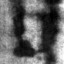

In [26]:
from PIL import Image
image = Image.open("sample_patches.png")
display(image)

In [27]:
labels = [
"a steel surface with scratches",
"a steel surface with cracks",
"a steel surface with pits",
"a steel surface with patches",
"a steel surface with inclusions",
"a steel surface with scale"
]

In [11]:
results = clip_classifier(
image,
candidate_labels=labels
)
results

[{'score': 0.5660211443901062, 'label': 'a steel surface with scratches'},
 {'score': 0.3154464662075043, 'label': 'a steel surface with inclusions'},
 {'score': 0.0808330774307251, 'label': 'a steel surface with patches'},
 {'score': 0.016999533399939537, 'label': 'a steel surface with cracks'},
 {'score': 0.011164909228682518, 'label': 'a steel surface with scale'},
 {'score': 0.009534965269267559, 'label': 'a steel surface with pits'}]

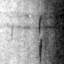

[{'score': 0.740272045135498, 'label': 'a steel surface with scratches'},
 {'score': 0.08364124596118927, 'label': 'a steel surface with patches'},
 {'score': 0.0653352290391922, 'label': 'a steel surface with cracks'},
 {'score': 0.04232317581772804, 'label': 'a steel surface with inclusions'},
 {'score': 0.03707157447934151, 'label': 'a steel surface with scale'},
 {'score': 0.03135685250163078, 'label': 'a steel surface with pits'}]

In [12]:
from PIL import Image
image = Image.open("sample_inclusions.png")
display(image)
results = clip_classifier(
image,
candidate_labels=labels
)
results

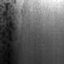

[{'score': 0.6249877214431763, 'label': 'a steel surface with scratches'},
 {'score': 0.21889059245586395, 'label': 'a steel surface with inclusions'},
 {'score': 0.072207510471344, 'label': 'a steel surface with scale'},
 {'score': 0.04442046955227852, 'label': 'a steel surface with patches'},
 {'score': 0.026791056618094444, 'label': 'a steel surface with pits'},
 {'score': 0.012702597305178642, 'label': 'a steel surface with cracks'}]

In [13]:
from PIL import Image
image = Image.open("sample_pitted_surfaces.png")
display(image)
results = clip_classifier(
image,
candidate_labels=labels
)
results

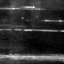

[{'score': 0.5773817896842957, 'label': 'a steel surface with scratches'},
 {'score': 0.16431918740272522, 'label': 'a steel surface with inclusions'},
 {'score': 0.09917482733726501, 'label': 'a steel surface with patches'},
 {'score': 0.06992928683757782, 'label': 'a steel surface with scale'},
 {'score': 0.06630389392375946, 'label': 'a steel surface with pits'},
 {'score': 0.02289099059998989, 'label': 'a steel surface with cracks'}]

In [14]:
from PIL import Image
image = Image.open("sample_scratches.png")
display(image)
results = clip_classifier(
image,
candidate_labels=labels
)
results

In [15]:
#Question 1: Did CLIP identify the defect correctly?
#It only identified the defect correctly in 1 of the 4 examples.

#Question 2: How does this differ from the CNN you trained in Lab 4?
#This model seems to be much less precise than the CNN trained in Lab 4. This is an expected result for a zero-shot foundation model on specialized tasks.

#Question 3: How many defect images did CLIP train on during today's laboratory?
#None.

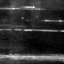

[{'score': 0.2808612883090973, 'label': 'a steel surface with inclusions'},
 {'score': 0.2776431739330292, 'label': 'scratches'},
 {'score': 0.1695137917995453, 'label': 'a steel surface with patches'},
 {'score': 0.11952608823776245, 'label': 'a steel surface with scale'},
 {'score': 0.11332940310239792, 'label': 'a steel surface with pits'},
 {'score': 0.03912624716758728, 'label': 'a steel surface with cracks'}]

In [16]:
from PIL import Image
image = Image.open("sample_scratches.png")
display(image)
labels = [
"scratches",
"a steel surface with cracks",
"a steel surface with pits",
"a steel surface with patches",
"a steel surface with inclusions",
"a steel surface with scale"
]
results = clip_classifier(
image,
candidate_labels=labels
)
results


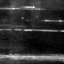

[{'score': 0.580005943775177, 'label': 'a photograph of scratches'},
 {'score': 0.16329890489578247, 'label': 'a steel surface with inclusions'},
 {'score': 0.09855902194976807, 'label': 'a steel surface with patches'},
 {'score': 0.06949508190155029, 'label': 'a steel surface with scale'},
 {'score': 0.06589219719171524, 'label': 'a steel surface with pits'},
 {'score': 0.022748855873942375, 'label': 'a steel surface with cracks'}]

In [17]:
from PIL import Image
image = Image.open("sample_scratches.png")
display(image)
labels = [
"a photograph of scratches",
"a steel surface with cracks",
"a steel surface with pits",
"a steel surface with patches",
"a steel surface with inclusions",
"a steel surface with scale"
]
results = clip_classifier(
image,
candidate_labels=labels
)
results

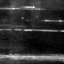

[{'score': 0.8635691404342651,
  'label': 'a photograph of a steel surface containing long linear scratches'},
 {'score': 0.05304596945643425, 'label': 'a steel surface with inclusions'},
 {'score': 0.03201588615775108, 'label': 'a steel surface with patches'},
 {'score': 0.022574761882424355, 'label': 'a steel surface with scale'},
 {'score': 0.02140440233051777, 'label': 'a steel surface with pits'},
 {'score': 0.007389731705188751, 'label': 'a steel surface with cracks'}]

In [18]:
from PIL import Image
image = Image.open("sample_scratches.png")
display(image)
labels = [
"a photograph of a steel surface containing long linear scratches",
"a steel surface with cracks",
"a steel surface with pits",
"a steel surface with patches",
"a steel surface with inclusions",
"a steel surface with scale"
]
results = clip_classifier(
image,
candidate_labels=labels
)
results

In [5]:
import pandas as pd

Model = [
    {'Prompt': 'scratches', 'Correct Class Score': 0.2776},
    {'Prompt': 'a photograph of scratches', 'Correct Class Score': 0.5800},
    {'Prompt': 'detailed engineering description', 'Correct Class Score': 0.8636},
]
df = pd.DataFrame(Model)
df.columns = ['Prompt', 'Correct Class Score']
df

,Prompt,Correct Class Score
0,scratches,0.2776
1,a photograph of scratches,0.5800
2,detailed engineering description,0.8636


In [ ]:
#Question 4: Does changing the wording affect the prediction?
#Yes, it does.

#Question 5: What does this suggest about using natural language as part of a model interface?
#More detailed feature descripions seem to improve the capacity of the model to recognize said features.

In [22]:
#Question 6: Which performs better on your steel-defect examples: your trained CNN from Lab 4 or zero-shot CLIP?
#The trained CNN from Lab 4 performs much better than this zero-shot CLIP.

#Question 7: Why might a specialized CNN outperform a much larger pretrained model on this narrow engineering task?
#"Jack of all trades, master of none": This zero-shot CLIP is a foundation model designed to learn general image-language relationships. It knows broad relationships in many domains but is not specialized enough to perform well on a niche image classification task.

In [28]:
from transformers import pipeline
llm = pipeline(
"text-generation",
model="HuggingFaceTB/SmolLM2-360M-Instruct",
device=0 if torch.cuda.is_available() else -1
)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

In [24]:
messages = [
  {
    "role": "user",
    "content":
    "Explain bearing vibration "
    "to a first-year engineering student."
  }
]
response = llm(
  messages,
  max_new_tokens=120
)
print(
  response[0]["generated_text"][-1]["content"]
)

Bearing vibration is a common phenomenon in engineering where the vibration of a bearing is a result of the imbalance between the inertial and damping forces acting on the bearing. This occurs when there is a mismatch between the normal force exerted on the bearing by the surrounding material, and the normal force that is resisted by the material itself.

The normal force exerted on a bearing by the surrounding material can be thought of as a force that acts perpendicular to the surface of the bearing. However, the force that is resisted by the bearing itself is a force that acts in the opposite direction, perpendicular to the surface


In [25]:
#Question 8: Is the response understandable?
#The wording is a bit uncanny, but it is understandable after all.

#Question 9: Is every statement necessarily correct because it came from an LLM?
#No. LLMs can hallucinate misleading or completely wrong statements.

In [26]:
messages = [
{
"role": "user",
"content":
"Explain bearing failure"
}
]
response = llm(
messages,
max_new_tokens=120
)
print(
response[0]["generated_text"][-1]["content"]
)

A bearing failure is a type of failure in aircraft, where a bearing (a type of bearing member in a flight control system) fails to rotate in the desired direction, resulting in a loss of altitude and possibly even a stall of the aircraft. This failure can occur due to various reasons such as mechanical failure, thermal stress, or electrical instability.

Bearing failure can arise from a wide range of issues, including a faulty bearing member, a failure in the electrical circuit connecting the bearing to the control system, or an internal electrical malfunction. The failure can be caused by an electromagnetic interference (EM


In [27]:
messages = [
{
"role": "user",
"content":
"You are assisting a mechanical engineering student. Explain three common causes of bearing failure. For each cause provide:"
"1. the cause,"
"2. one observable symptom,"
"3. one possible corrective action."
"Keep the response below 150 words."
}
]
response = llm(
messages,
max_new_tokens=120
)
print(
response[0]["generated_text"][-1]["content"]
)

1. Cause: Wear and tear on the bearing surface due to excessive use or lack of coolant. Symptoms: Increased noise, vibration, and oil leaks. Possible corrective action: Regularly check for signs of excessive wear, replace bearings when necessary, and ensure adequate coolant flow.

2. Cause: Incorrect lubrication practices such as improper or inadequate lubricant levels, over-lubrication, or the use of low-quality lubricants. Symptoms: Creep, overheating, or excessive wear. Possible corrective action: Conduct regular lubricant changes, keep oil levels topped-up, and use high-quality lubric


In [28]:
#Question 10: Which response is easier to use?
#Even though I think both answers are at least somewhat deficient, I think the answer from Prompt B is more general and, hence, easier to use.

#Question 11: What information in Prompt B helped the model?
#Probably the clear and ordered steps to follow in order to answer the question.

In [8]:
messages = [
{
"role": "user",
"content": (
"Role:\n"
"You are an engineering maintenance assistant.\n\n"
"Task:\n"
"Analyze the maintenance observation.\n\n"
"Context:\n"
"A centrifugal pump has increased vibration.\n\n"
"Constraint:\n"
"Do not invent measurements.\n\n"
"Output:\n"
"Give three possible causes in a table."
)
}
]
response = llm(
messages,
max_new_tokens=120
)
print(
response[0]["generated_text"][-1]["content"]
)

A) Frequency of pump operation: The pump operation time and design parameters can cause increased vibration.

B) Gearbox and gear train: Improper gear ratios or broken gears can cause increased vibration.

C) Environmental factors: High temperatures and humidity can cause increased vibration.


In [9]:
response = llm(
messages,
max_new_tokens=120,
do_sample=True,
temperature=0.2
)

In [10]:
messages = [
{
"role": "user",
"content":
"Explain bearing vibration "
"to a first-year engineering student."
}
]
response = llm(
messages,
max_new_tokens=120
)
print(
response[0]["generated_text"][-1]["content"]
)

Bearing vibration is the repetitive, oscillating motion of a bearing, caused by the interaction between the bearing and the surrounding environment. It is often seen in industrial machinery, particularly those with rotating components, such as pumps, gearboxes, or transmission systems.

Imagine a bearing, like a ball bearing, inside a machine, and think of the surrounding environment, such as a machine's bearings and its components, as a series of oscillating fields or waves. These fields are like a grid of sine waves, alternating between positive and negative values.

When the bearings move, they also move


In [11]:
response = llm(
messages,
max_new_tokens=120,
do_sample=True,
temperature=1.0
)

In [12]:
messages = [
{
"role": "user",
"content":
"Explain bearing vibration "
"to a first-year engineering student."
}
]
response = llm(
messages,
max_new_tokens=120
)
print(
response[0]["generated_text"][-1]["content"]
)

Bearing vibration, in a mechanical engineering context, refers to the dynamic movement or oscillation of a mechanical system, such as a bearing, caused by the relative movement between moving parts. It occurs when the parts of a machine or a structure that are in contact with each other experience vibrations due to the movement of the other parts.

In a bearing, for example, when a bearing is subjected to vibration, it can be caused by the movement of the inner and outer rings of the bearing, which can move relative to each other. This relative movement can be due to various factors such as friction,


In [13]:
#Question 12: Which setting produces more variation?
#Temperature set to 1.0 produces more variation as expected, since it is farther from 0.

#Question 13: For an engineering assistant, when might lower randomness be preferable?
#In situations where consistency and rule-following are critical, such as for mathematical calculations.

In [29]:
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer(
"sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [56]:
manual = [
  """Excessive bearing vibration may result from imbalance, shaft misalignment, looseness, or bearing damage.""",
  """Bearing overheating may be caused by excessive load, inadequate lubrication, excessive lubrication, or incorrect installation.""",
  """Pump cavitation may produce a rattling or gravel-like sound, fluctuating pressure, vibration, and damage to the impeller.""",
  """Shaft misalignment can create increased vibration, coupling wear, and elevated bearing temperatures.""",
  """Belt slippage can result from inadequate belt tension, contamination, or worn belt surfaces.""",
  """Before servicing rotating machinery, isolate the energy source and follow appropriate lockout procedures."""
]

In [57]:
manual_embeddings = embedding_model.encode(
manual,
normalize_embeddings=True
)
print(manual_embeddings.shape)

(6, 384)


In [58]:
query = """
The pump sounds like gravel is moving
inside it and the discharge pressure
keeps changing.
"""
query_embedding = embedding_model.encode(
[query],
normalize_embeddings=True
)

In [18]:
scores = (
query_embedding
@ manual_embeddings.T
)[0]
best_index = np.argmax(scores)
print("Best passage:")
print(manual[best_index])
print("Similarity:", scores[best_index])

Best passage:
Pump cavitation may produce a rattling
  or gravel-like sound, fluctuating pressure,
  vibration, and damage to the impeller.
Similarity: 0.6153228


In [20]:
#Question 14: Which section was retrieved?
#The section about pump cavitation producing a rattling or gravel-like sound, fluctuating pressure, vibration, and damage to the impeller.

#Question 15: Did semantic search retrieve the passage you expected?
#Yes. The passage matched the problem description of a gravel-moving sound and pressure fluctuations.

In [59]:
def retrieve(query, k=2):
  q = embedding_model.encode(
    [query],
    normalize_embeddings=True
  )
  scores = (q @ manual_embeddings.T)[0]
  indices = np.argsort(scores)[-k:][::-1]
  return [manual[i] for i in indices]

In [60]:
retrieve("Why is my bearing getting hot?")

['Bearing overheating may be caused by excessive load, inadequate lubrication, excessive lubrication, or incorrect installation.',
 'Excessive bearing vibration may result from imbalance, shaft misalignment, looseness, or bearing damage.']

In [61]:
def build_prompt(question, context):
  context_text = "\n\n".join(context)
  return f"""
You are a mechanical engineering maintenance assistant.
Answer the question using ONLY the provided
maintenance information.
If the information is insufficient, say:
"I cannot determine this from the provided
maintenance information."
Maintenance information:
{context_text}
Question:
{question}
Give a concise engineering answer.
"""

In [62]:
def engineering_assistant(question):
  context = retrieve(question, k=2)
  prompt = build_prompt(question, context)
  messages = [
    {
      "role": "user",
      "content": prompt
    }
  ]
  result = llm(
    messages,
    max_new_tokens=150
  )
  answer = (
    result[0]
    ["generated_text"][-1]
    ["content"]
  )
  return answer

In [16]:
print(
engineering_assistant(
"The pump is rattling and pressure is "
"fluctuating. What should I investigate?"
)
)

To investigate the issue, start examining the pump's components, particularly the shaft and bearings. Look for signs of bearing damage, such as cracks, wear patterns, or uneven wear. Check for any misalignment issues that could be contributing to the rattling. Ensure that the pump's components are properly aligned and have sufficient clearance to allow smooth operation.


In [17]:
print(
  engineering_assistant(
    "Why might a bearing overheat?"
  )
)

Bearings may overheat due to excessive load, inadequate lubrication, excessive lubrication, or incorrect installation.


In [18]:
print(
  engineering_assistant(
    "What could cause shaft vibration?"
  )
)

Excessive bearing vibration may result from imbalance, shaft misalignment, or bearing damage.


In [19]:
print(
  engineering_assistant(
    "What are symptoms of cavitation?"
  )
)

Cavitation can produce a rattling or gravel-like sound, fluctuating pressure, vibration, and damage to the impeller. Excessive bearing vibration may result from imbalance, shaft misalignment, loosening, or bearing damage.


In [20]:
print(
  engineering_assistant(
    "Why might a belt slip?"
  )
)

Belt slippage can result from inadequate belt tension, contamination, or worn belt surfaces.


In [21]:
print(
  engineering_assistant(
    "What should I do before servicing machinery?"
  )
)

"Before servicing rotating machinery, isolate the energy source and follow appropriate lockout procedures."


In [27]:
import pandas as pd

Question = [
    {'Question': 'Why might a bearing overheat?', 'Relevant Information Retrieved?': 'Yes', 'Answer Useful?': 'Yes'},
    {'Question': 'What could cause shaft vibration?', 'Relevant Information Retrieved?': 'Yes', 'Answer Useful?': 'Yes'},
    {'Question': 'What are symptoms of cavitation?', 'Relevant Information Retrieved?': 'Yes', 'Answer Useful?': 'Yes'},
    {'Question': 'Why might a belt slip?', 'Relevant Information Retrieved?': 'Yes', 'Answer Useful?': 'Yes'},
    {'Question': 'What should I do before servicing machinery?', 'Relevant Information Retrieved?': 'Yes', 'Answer Useful?': 'Yes'},
]
df = pd.DataFrame(Question)
df.columns = ['Question', 'Relevant Information Retrieved?', 'Answer Useful?']
df

,Question,Relevant Information Retrieved?,Answer Useful?
0,Why might a bearing overheat?,Yes,Yes
1,What could cause shaft vibration?,Yes,Yes
2,What are symptoms of cavitation?,Yes,Yes
3,Why might a belt slip?,Yes,Yes
4,What should I do before servicing machinery?,Yes,Yes


In [28]:
print(
  engineering_assistant(
    "What torque should I use to tighten the bearing housing bolts?"
  )
)

To tighten the bearing housing bolts, you should apply a torque of 100-120 Nm.


In [29]:
#Question 16: What did the model answer?
#The model hallucinated an answer of 100-120 Nm.

#Question 17: Did it correctly admit that the information was unavailable?
#It did not.

#Question 18: Why is this behavior important in engineering?
#Hallucination prevention is important in engineering so that the user does not receive a misleading or incorrect answer that they might apply to critical systems.

In [37]:
messages = [{
  "role": "user",
  "content": 'What can I do to prevent bearing failure?',
}]
response = llm(
  messages,
  max_new_tokens=120
)
print(
  response[0]["generated_text"][-1]["content"]
)

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In this case, it seems you are asking about prevention. The answer is a combination of preventive measures and technologies. Here are some steps you can follow to prevent bearing failure:

1. **Regular Maintenance and Inspection**: Regularly check your bearings for signs of wear and tear. Inspect the bearings every 10,000 miles (16,000 kilometers) or every 12 months, whichever comes first. Replace bearings if they show signs of failure or wear.

2. **Drain the Brake Fluid**: Ensure your brake fluid is not leaking. Dispose of


In [35]:
engineering_assistant('What can I do to prevent bearing failure?')

'To prevent bearing failure, ensure that the bearing is properly lubricated, the load is manageable, and the system is functioning within the optimal parameters.'

In [42]:
import pandas as pd

Question = [
    {'Property': 'Uses provided manual', 'LLM Alone': 'No', 'RAG': 'Yes'},
    {'Property': 'Answer traceable to supplied source', 'LLM Alone': 'Limited', 'RAG': 'Better'},
    {'Property': 'Risk of unsupported claims', 'LLM Alone': 'High', 'RAG': 'Low'},
    {'Property': 'Domain specificity', 'LLM Alone': 'No (general)', 'RAG': 'Yes (customized)'},
]
df = pd.DataFrame(Question)
df.columns = ['Property', 'LLM Alone', 'RAG']
df

,Property,LLM Alone,RAG
0,Uses provided manual,No,Yes
1,Answer traceable to supplied source,Limited,Better
2,Risk of unsupported claims,High,Low
3,Domain specificity,No (general),Yes (customized)


In [44]:
#Question 19: Does retrieval make the answer automatically correct? Explain.
#No. Even though the retrieved text may be correct, the model may wrongly establish a connection with a question that does not apply to the retrieved answers. The model can also create a Frankenstein answer blending correct facts into a wrong or misleading hallucination.

In [36]:
import gradio as gr
app = gr.Interface(
fn=engineering_assistant,
inputs=gr.Textbox(
lines=3,
label="Maintenance Question"
),
outputs=gr.Textbox(
label="Assistant Response"
),
title="Mechanical Maintenance Assistant",
description=(
"A small local RAG system using "
"open pretrained models."
)
)
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ba0b1312881d65ab47.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
#Modification done: return the two retrieved passage with the answer.
#Engineering problem aimed to solve: source tractability.

In [95]:
def engineering_assistant_with_sources(question):
    # Retrieve top 2 most relevant passages
    context = retrieve(question, k=2)
    prompt = build_prompt(question, context)
    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]
    result = llm(
        messages,
        max_new_tokens=150
    )
    answer = result[0]["generated_text"][-1]["content"]

    # Format the source passages clearly
    sources_text = f"Source 1: {context[0]}\nSource 2: {context[1]}"

    return answer, sources_text

In [89]:
engineering_assistant_with_sources('What could cause shaft vibration?')

('Shaft misalignment can create increased vibration, coupling wear, and elevated bearing temperatures.',
 'Source 1: Excessive bearing vibration may result from imbalance, shaft misalignment, looseness, or bearing damage.\nSource 2: Shaft misalignment can create increased vibration, coupling wear, and elevated bearing temperatures.')

In [94]:
import gradio as gr
# Launch an updated Gradio interface displaying both the response and the verified source texts
app = gr.Interface(
    fn=engineering_assistant_with_sources,
    inputs=gr.Textbox(
        lines=3,
        label="Maintenance Question"
    ),
    outputs=[
        gr.Textbox(label="Assistant Response"),
        gr.Textbox(label="Retrieved Source Passages (for Verification)")
    ],
    title="Mechanical Maintenance Assistant (With Source Verification)",
    description=(
        "A small local RAG system using open pretrained models that outputs both the model's answer "
        "and the exact retrieved source passages."
    )
)
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7b2855ef5b96d39a47.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [93]:
import pandas as pd

Question = [
    {'Question': 'What could cause bearing overheating?', 'Correct Retrieval?': 'Yes', 'Grounded Answer?': 'Yes', 'Problem Observed': 'None'},
    {'Question': 'What can I do to prevent bearing failure?', 'Correct Retrieval?': 'Yes', 'Grounded Answer?': 'Yes', 'Problem Observed': 'None'},
    {'Question': 'What are the consequences of shaft misalignment?', 'Correct Retrieval?': 'Yes', 'Grounded Answer?': 'Yes', 'Problem Observed': 'None'},
    {'Question': 'What are symptoms of cavitation?', 'Correct Retrieval?': 'Yes', 'Grounded Answer?': 'No', 'Problem Observed': 'Partial answer'},
    {'Question': 'Why might a belt slip?', 'Correct Retrieval?': 'Yes', 'Grounded Answer?': 'Yes', 'Problem Observed': 'None'},
    {'Question': 'U1: Why is the pink blue whale flying around my kitchen?', 'Correct Retrieval?': 'No', 'Grounded Answer?': 'No', 'Problem Observed': 'Hallucination'},
    {'Question': 'U2: The magic rabbit said yes!', 'Correct Retrieval?': 'No', 'Grounded Answer?': 'No', 'Problem Observed': 'Hallucination'},
]
df = pd.DataFrame(Question)
df.columns = ['Question', 'Correct Retrieval?', 'Grounded Answer?', 'Problem Observed']
df

,Question,Correct Retrieval?,Grounded Answer?,Problem Observed
0,What could cause bearing overheating?,Yes,Yes,None
1,What can I do to prevent bearing failure?,Yes,Yes,None
2,What are the consequences of shaft misalignment?,Yes,Yes,None
3,What are symptoms of cavitation?,Yes,No,Partial answer
4,Why might a belt slip?,Yes,Yes,None
5,U1: Why is the pink blue whale flying around m...,No,No,Hallucination
6,U2: The magic rabbit said yes!,No,No,Hallucination


In [ ]:
#System failures:
#Unsupported information generated: the problem was caused primarily by hallucinations during the answer generation.
#Important information omitted: the problem was caused primarily by a partial retrieval of the knowledge base.
#Ambiguous prompt: the problem was caused primarily by the user question being designed to try to make the model hallucinate.

In [96]:
#R1: What is the main difference between the CNN you trained in Lab 4 and CLIP used in this laboratory?
#The CNN trained in Lab 4 was specifically designed to solve a niche engineering classification problem, while the CLIP model used in this lab is broadly trained to recognize general image-language relationships without being specialized in any area.

#R2: What does zero-shot learning mean?
#It is the ability of a model to recognize categories or classifications it has not been directly trained on.

#R3: Why can prompt wording change model behavior?
#Because LLMs generate the answer based on token probabilities, so small word changes can switch how the system reads the prompt.

#R4: Why should an LLM-generated engineering answer be verified?
#LLMs base their answers on probability likelihoods. They do not understand what they are generating; they just output what fits best based on how they were tuned.

#R5: What is an embedding?
#An embedding is the representation of data as numerical vectors.

#R6: Why can semantic search retrieve information even when the question uses different words?
#Because the model concludes that the question's embedded meaning matches the retrieved information's embedded meaning.

#R7: What problem does RAG attempt to address?
#RAG attempts to reduce model hallucinations and increase answer verifiability, among other source-related problems.

#R8: Why can a RAG system still produce an incorrect answer?
#Yes. It can incorrectly retrieve the source, generating a misleading or completely wrong answer.

#R9: Which part of your system would you trust least in a safety-critical application, and why?
#The system has a very limited amount of sources. I would not trust this model in any safety-critical situation.

#R10: What additional controls would be required before deploying an LLM-based assistant in an industrial environment?
#Since the model would be deployed in a specific industrial environment, I would try to make the model as deterministic as possible. Also, I would not let the model make decisions in critical areas; in those cases, I would restrict it only to an advisory role.